<a href="https://colab.research.google.com/github/zohaibahmedshaikh32-coder/Machine_Learning_labs/blob/main/ML_LAB_10_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Import necessary libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score, confusion_matrix

# Set plot visual style
sns.set_theme(style="whitegrid")

In [ ]:
# Task 1: Load the Iris Dataset
iris = load_iris()

# Convert to pandas DataFrame for easier data manipulation
df = pd.DataFrame(data=iris.data, columns=iris.feature_names)

# View first few rows and summary
print("--- Dataset Head ---")
print(df.head())

print("\n--- Dataset Info ---")
print(df.info())

--- Dataset Head ---
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2

--- Dataset Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 4 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
dtypes: float64(4)
memory usage: 4.8 KB
None


--- 1. Dataset Shape & Info ---
Total Rows and Columns: (150, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   Cluster            150 non-null    int32  
dtypes: float64(4), int32(1)
memory usage: 5.4 KB
None

--- 2. Missing Values Check ---
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
Cluster              0
dtype: int64

--- 3. Statistical Summary ---
       sepal length (cm)  sepal width (cm)  petal length (cm)  \
count         150.000000        150.000000         150.000000   
mean            5.843333          3.057333           3.758000   
std             0.828066          0.435866          

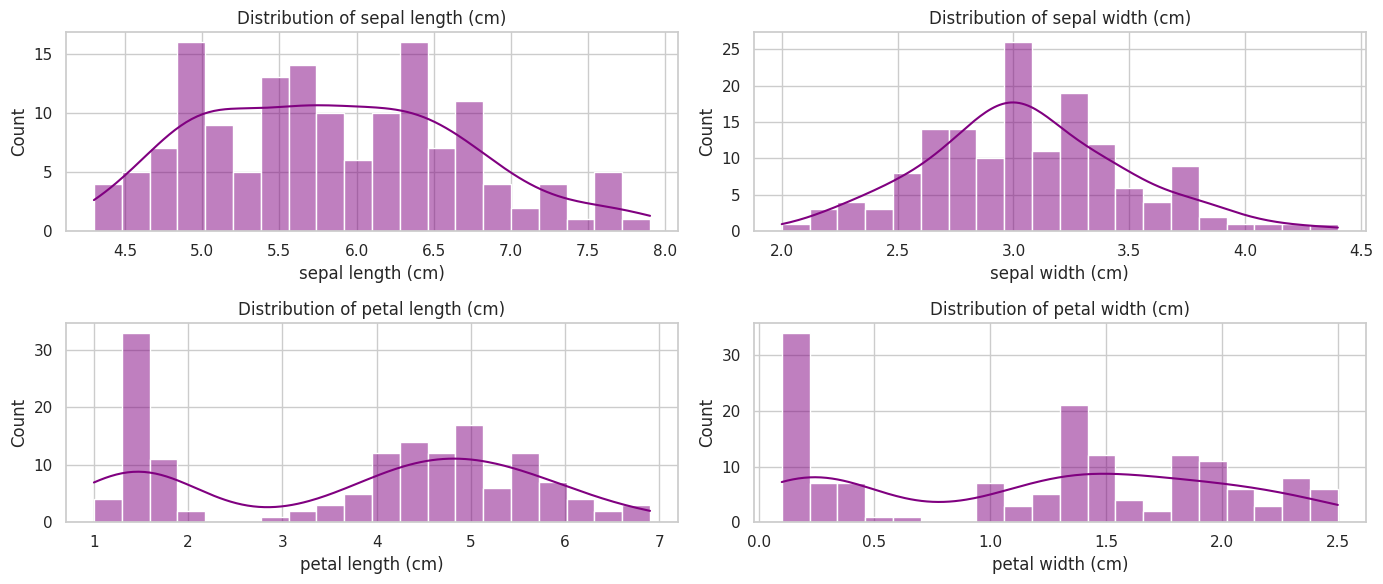


--- Preprocessed (Scaled) Data Head ---
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0          -0.900681          1.019004          -1.340227         -1.315444
1          -1.143017         -0.131979          -1.340227         -1.315444
2          -1.385353          0.328414          -1.397064         -1.315444
3          -1.506521          0.098217          -1.283389         -1.315444
4          -1.021849          1.249201          -1.340227         -1.315444


In [ ]:
# ==========================================
# TASK 2: Exploratory Data Analysis (EDA) & Scaling
# ==========================================

print("--- 1. Dataset Shape & Info ---")
print(f"Total Rows and Columns: {df.shape}")
print(df.info())

print("\n--- 2. Missing Values Check ---")
print(df.isnull().sum())

print("\n--- 3. Statistical Summary ---")
print(df.describe())

# --- 4. EDA Visualizations ---
# Figure 1: Feature Distributions (Histograms + KDE)
plt.figure(figsize=(14, 6))
for i, col in enumerate(df.columns[:-1]): # exclude target/cluster column if any
    plt.subplot(2, 2, i+1)
    sns.histplot(df[col], kde=True, color='purple', bins=20)
    plt.title(f"Distribution of {col}")
plt.tight_layout()
plt.show()

# ==========================================
# 5. Feature Normalization / Scaling
# ==========================================
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df.iloc[:, :-1]) # Scaling only feature columns

# Convert scaled arrays back into a dataframe for quick inspection
df_scaled = pd.DataFrame(X_scaled, columns=df.columns[:-1])

print("\n--- Preprocessed (Scaled) Data Head ---")
print(df_scaled.head())

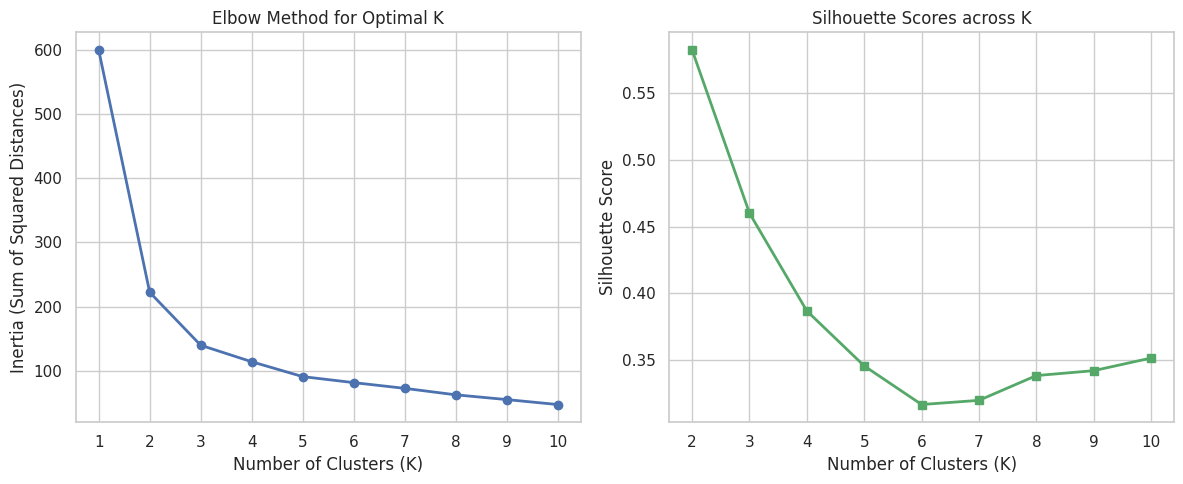


Observation:
The 'Elbow Point' clearly forms at K = 3, where inertia reduction slows down drastically.


In [ ]:
# Task 3: Elbow Method & Silhouette Score Calculation
inertia_list = []
silhouette_list = []
K_range = range(1, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia_list.append(kmeans.inertia_)

    # Silhouette score requires at least 2 clusters
    if k > 1:
        silhouette_list.append(silhouette_score(X_scaled, kmeans.labels_))

# Plotting the Elbow Curve
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(K_range, inertia_list, marker='o', color='b', linewidth=2)
plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia (Sum of Squared Distances)")
plt.xticks(K_range)

plt.subplot(1, 2, 2)
plt.plot(range(2, 11), silhouette_list, marker='s', color='g', linewidth=2)
plt.title("Silhouette Scores across K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.xticks(range(2, 11))

plt.tight_layout()
plt.show()

print("\nObservation:")
print("The 'Elbow Point' clearly forms at K = 3, where inertia reduction slows down drastically.")

In [ ]:
# Task 4: Model Training with Optimal K = 3
optimal_k = 3
kmeans_model = KMeans(n_clusters=optimal_k, init='k-means++', random_state=42, n_init=10)

# Fit model and predict cluster assignments
df['Cluster'] = kmeans_model.fit_predict(X_scaled)

print("--- Cluster Centers (Scaled Features) ---")
print(kmeans_model.cluster_centers_)

print("\n--- Cluster Counts ---")
print(df['Cluster'].value_counts())

--- Cluster Centers (Scaled Features) ---
[[-0.05021989 -0.88337647  0.34773781  0.2815273 ]
 [-1.01457897  0.85326268 -1.30498732 -1.25489349]
 [ 1.13597027  0.08842168  0.99615451  1.01752612]]

--- Cluster Counts ---
Cluster
0    53
1    50
2    47
Name: count, dtype: int64


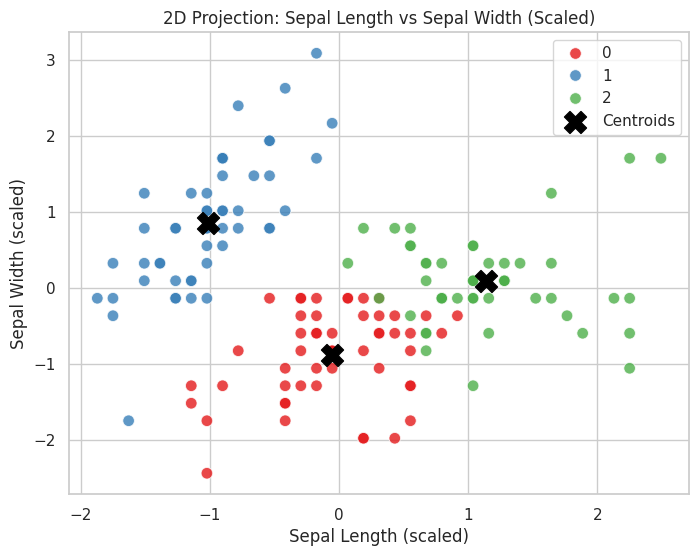

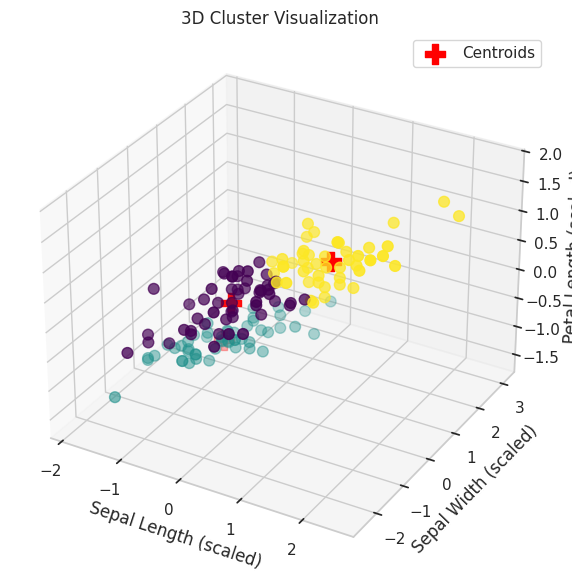

In [ ]:
# Task 5: Cluster Visualizations

# --- 2D Visualizations (Pairplot & Feature Scatter) ---
plt.figure(figsize=(8, 6))
sns.scatterplot(
    x=X_scaled[:, 0], y=X_scaled[:, 1],
    hue=df['Cluster'], palette='Set1', s=70, alpha=0.8
)
# Plot cluster centroids
centroids = kmeans_model.cluster_centers_
plt.scatter(centroids[:, 0], centroids[:, 1], s=250, c='black', marker='X', label='Centroids')

plt.title("2D Projection: Sepal Length vs Sepal Width (Scaled)")
plt.xlabel("Sepal Length (scaled)")
plt.ylabel("Sepal Width (scaled)")
plt.legend()
plt.show()

# --- 3D Visualization ---
fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection='3d')

scatter = ax.scatter(
    X_scaled[:, 0], X_scaled[:, 1], X_scaled[:, 2],
    c=df['Cluster'], cmap='viridis', s=60
)

# Plot centroids in 3D space
ax.scatter(centroids[:, 0], centroids[:, 1], centroids[:, 2], s=200, c='red', marker='P', label='Centroids')

ax.set_title("3D Cluster Visualization")
ax.set_xlabel("Sepal Length (scaled)")
ax.set_ylabel("Sepal Width (scaled)")
ax.set_zlabel("Petal Length (scaled)")
plt.legend()
plt.show()

In [ ]:
# Task 6: Evaluation & Comparison with True Labels
y_true = iris.target

# Calculate Adjusted Rand Index (-1 to 1, higher is better)
ari_score = adjusted_rand_score(y_true, df['Cluster'])
final_silhouette = silhouette_score(X_scaled, df['Cluster'])

print(f"Final Silhouette Score: {final_silhouette:.4f}")
print(f"Adjusted Rand Index (ARI): {ari_score:.4f}")

# Cross-tabulation matrix (Comparing Predicted Clusters vs True Classes)
eval_df = pd.DataFrame({'True Label': iris.target_names[y_true], 'Cluster': df['Cluster']})
cm = pd.crosstab(eval_df['True Label'], eval_df['Cluster'], rownames=['Actual Class'], colnames=['Cluster Assigned'])

print("\n--- Confusion Matrix (Actual Class vs Cluster) ---")
print(cm)

Final Silhouette Score: 0.4599
Adjusted Rand Index (ARI): 0.6201

--- Confusion Matrix (Actual Class vs Cluster) ---
Cluster Assigned   0   1   2
Actual Class                
setosa             0  50   0
versicolor        39   0  11
virginica         14   0  36
